# ЛР 2 - регуляризация и KNN

## Импорты и воспроизводимость

In [53]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lin_reg import LinearRegression
from log_reg import LogisticRegression

SEED = 67
TRAIN_SIZE = 0.6
VAL_SIZE = 0.2

# Часть A. Регуляризация

к обычному loss добавляем штраф за большие веса. `bias` не регуляризируем.

Без регуляризации:

$$L = L_{data}$$

L1:

$$L = L_{data} + \lambda \sum_j |w_j|, \qquad \nabla_w L_{reg} = \lambda \operatorname{sign}(w)$$

L2:

$$L = L_{data} + \lambda \sum_j w_j^2, \qquad \nabla_w L_{reg} = 2\lambda w$$

ElasticNet:

$$L = L_{data} + \lambda \left[\alpha\sum_j|w_j| + (1-\alpha)\sum_jw_j^2\right]$$

в моделях `regularization` выбирает вид штрафа, `lambda_` задаёт его силу, `l1_ratio` - долю L1 в ElasticNet.

## Как выбираем регуляризацию

данные делим на `train / validation / test` в пропорции 60/20/20. На train обучаем веса, по validation выбираем $\lambda$, test пока не используем.

для всех вариантов оставляем одинаковые split, preprocessing, начальные веса, learning rate и количество эпох.

# Linear Regression

In [54]:
bike_df = pd.read_csv("data/day.csv", parse_dates=["dteday"])
print("Размер:", bike_df.shape)
bike_df.head()

Размер: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


## Подготовка данных

подготовка такая же, как в первой лабе. `cnt` записываем в $y$, удаляем `casual` и `registered`, потому что $cnt = casual + registered$. Идентификатор и дату тоже не используем.

In [55]:
y = bike_df["cnt"]
X = bike_df.drop(columns=["cnt", "casual", "registered", "instant", "dteday"])

print("X:", X.shape)
print("y:", y.shape)

X: (731, 11)
y: (731,)


### Train/validation/test split

перемешиваем индексы один раз. Все варианты регуляризации получат одни и те же объекты.

In [56]:
indices = np.random.default_rng(SEED).permutation(len(X))
train_end = int(len(X) * TRAIN_SIZE)
val_end = int(len(X) * (TRAIN_SIZE + VAL_SIZE))

train_idx = indices[:train_end]
val_idx = indices[train_end:val_end]
test_idx = indices[val_end:]

X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].to_numpy()
y_val = y.iloc[val_idx].to_numpy()
y_test = y.iloc[test_idx].to_numpy()

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (438, 11)
Validation: (146, 11)
Test: (147, 11)


### Preprocessing

категории кодируем через `get_dummies`. Числовые признаки масштабируем параметрами train, потому что штраф применяется к весам и признаки должны иметь сопоставимый масштаб.

In [57]:
cat_cols = ["season", "mnth", "weekday", "weathersit"]
num_cols = X_train.columns.difference(cat_cols)

X_train = pd.get_dummies(X_train, columns=cat_cols, dtype=int)
X_val = pd.get_dummies(X_val, columns=cat_cols, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, dtype=int)

X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

means = X_train[num_cols].mean()
stds = X_train[num_cols].std().replace(0, 1)

X_train[num_cols] = (X_train[num_cols] - means) / stds
X_val[num_cols] = (X_val[num_cols] - means) / stds
X_test[num_cols] = (X_test[num_cols] - means) / stds

linear_feature_names = X_train.columns
X_test_linear = X_test.copy()
y_test_linear = y_test.copy()

print("Признаков после preprocessing:", X_train.shape[1])

Признаков после preprocessing: 33


## Подбор $\lambda$

для каждой регуляризации проверяем несколько значений $\lambda$. Для ElasticNet дополнительно подбираем `l1_ratio`. Выбираем вариант с минимальным RMSE на validation.

In [58]:
regularizations = ["none", "l1", "l2", "elasticnet"]
linear_lambdas = [0.001, 0.01, 0.1, 1, 10]
elasticnet_ratios = [0.25, 0.5, 0.75]

linear_models = {}
linear_search = []

for reg in regularizations:
    candidates = [0] if reg == "none" else linear_lambdas
    ratios = elasticnet_ratios if reg == "elasticnet" else [0.5]
    best_rmse = np.inf

    for lambda_ in candidates:
        for l1_ratio in ratios:
            model = LinearRegression(
                learning_rate=0.01,
                epochs=2000,
                regularization=reg,
                lambda_=lambda_,
                l1_ratio=l1_ratio,
            )
            model.fit(X_train, y_train)

            val_pred = model.predict(X_val)
            val_rmse = np.sqrt(np.mean((y_val - val_pred) ** 2))
            ratio = l1_ratio if reg == "elasticnet" else np.nan
            linear_search.append([reg, lambda_, ratio, val_rmse])

            if val_rmse < best_rmse:
                best_rmse = val_rmse
                linear_models[reg] = model

linear_search = pd.DataFrame(
    linear_search, columns=["regularization", "lambda", "l1_ratio", "val_RMSE"]
)
linear_search.round(3)

,regularization,lambda,l1_ratio,val_RMSE
0,none,0.000,NaN,751.901
1,l1,0.001,NaN,751.901
2,l1,0.010,NaN,751.899
3,l1,0.100,NaN,751.882
4,l1,1.000,NaN,751.742
5,l1,10.000,NaN,754.546
6,l2,0.001,NaN,752.129
7,l2,0.010,NaN,755.758
8,l2,0.100,NaN,821.752
9,l2,1.000,NaN,1171.698


In [59]:
linear_best = (
    linear_search.sort_values("val_RMSE")
    .groupby("regularization", sort=False)
    .first()
    .sort_index()
)
linear_best.round(3)

,lambda,l1_ratio,val_RMSE
regularization,,,
elasticnet,0.001,0.75,751.954
l1,1.000,NaN,751.742
l2,0.001,NaN,752.129
none,0.000,NaN,751.901


# Logistic Regression

In [60]:
spaceship_df = pd.read_csv("data/train.csv")
print("Размер:", spaceship_df.shape)
spaceship_df.head()

Размер: (8693, 14)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


## Подготовка данных

повторяем preprocessing первой лабы. `Transported` - target. Удаляем почти уникальные `Name` и `PassengerId`, а `Cabin` делим на палубу, номер и сторону.

In [61]:
y = spaceship_df["Transported"].astype(int)
X = spaceship_df.drop(columns=["Transported", "Name", "PassengerId"])

cabin = X["Cabin"].str.split("/", expand=True)
X["Deck"] = cabin[0]
X["CabinNum"] = pd.to_numeric(cabin[1])
X["Side"] = cabin[2]
X = X.drop(columns="Cabin")

print("X:", X.shape)
print("y:", y.shape)

X: (8693, 13)
y: (8693,)


### Train / validation / test split

In [62]:
indices = np.random.default_rng(SEED).permutation(len(X))
train_end = int(len(X) * TRAIN_SIZE)
val_end = int(len(X) * (TRAIN_SIZE + VAL_SIZE))

train_idx = indices[:train_end]
val_idx = indices[train_end:val_end]
test_idx = indices[val_end:]

X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].to_numpy()
y_val = y.iloc[val_idx].to_numpy()
y_test = y.iloc[test_idx].to_numpy()

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (5215, 13)
Validation: (1739, 13)
Test: (1739, 13)


### Preprocessing

числовые пропуски заполняем медианой train, категориальные - модой train. После `get_dummies` масштабируем исходные числовые признаки.

In [63]:
num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns

for col in num_cols:
    median = X_train[col].median()
    X_train[col] = X_train[col].fillna(median)
    X_val[col] = X_val[col].fillna(median)
    X_test[col] = X_test[col].fillna(median)

for col in cat_cols:
    mode = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(mode)
    X_val[col] = X_val[col].fillna(mode)
    X_test[col] = X_test[col].fillna(mode)

X_train = pd.get_dummies(X_train, columns=cat_cols, dtype=int)
X_val = pd.get_dummies(X_val, columns=cat_cols, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, dtype=int)

X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

means = X_train[num_cols].mean()
stds = X_train[num_cols].std().replace(0, 1)
X_train[num_cols] = (X_train[num_cols] - means) / stds
X_val[num_cols] = (X_val[num_cols] - means) / stds
X_test[num_cols] = (X_test[num_cols] - means) / stds

logistic_feature_names = X_train.columns
X_test_logistic = X_test.copy()
y_test_logistic = y_test.copy()

print("Пропусков:", X_train.isna().sum().sum() + X_val.isna().sum().sum() + X_test.isna().sum().sum())
print("Признаков после preprocessing:", X_train.shape[1])

Пропусков: 0
Признаков после preprocessing: 27


## Подбор $\lambda$

обучаем все варианты в одинаковых условиях. Для ElasticNet перебираем $\lambda$ и `l1_ratio`, затем выбираем минимальный LogLoss на validation.

In [64]:
logistic_lambdas = [0.00001, 0.0001, 0.001, 0.01, 0.1]

logistic_models = {}
logistic_search = []

for reg in regularizations:
    candidates = [0] if reg == "none" else logistic_lambdas
    ratios = elasticnet_ratios if reg == "elasticnet" else [0.5]
    best_log_loss = np.inf

    for lambda_ in candidates:
        for l1_ratio in ratios:
            model = LogisticRegression(
                learning_rate=0.1,
                epochs=1000,
                regularization=reg,
                lambda_=lambda_,
                l1_ratio=l1_ratio,
            )
            model.fit(X_train, y_train)

            val_proba = model.predict_proba(X_val)
            val_proba = np.clip(val_proba, 1e-15, 1 - 1e-15)
            val_log_loss = -np.mean(
                y_val * np.log(val_proba)
                + (1 - y_val) * np.log(1 - val_proba)
            )
            ratio = l1_ratio if reg == "elasticnet" else np.nan
            logistic_search.append([reg, lambda_, ratio, val_log_loss])

            if val_log_loss < best_log_loss:
                best_log_loss = val_log_loss
                logistic_models[reg] = model

logistic_search = pd.DataFrame(
    logistic_search, columns=["regularization", "lambda", "l1_ratio", "val_LogLoss"]
)
logistic_search.round(4)

,regularization,lambda,l1_ratio,val_LogLoss
0,none,0.0000,NaN,0.4277
1,l1,0.0000,NaN,0.4277
2,l1,0.0001,NaN,0.4279
3,l1,0.0010,NaN,0.4292
4,l1,0.0100,NaN,0.4532
5,l1,0.1000,NaN,0.6653
6,l2,0.0000,NaN,0.4278
7,l2,0.0001,NaN,0.4279
8,l2,0.0010,NaN,0.4299
9,l2,0.0100,NaN,0.4529


In [65]:
logistic_best = (
    logistic_search.sort_values("val_LogLoss")
    .groupby("regularization", sort=False)
    .first()
    .sort_index()
)
logistic_best.round(4)

,lambda,l1_ratio,val_LogLoss
regularization,,,
elasticnet,0.0,0.75,0.4277
l1,0.0,NaN,0.4277
l2,0.0,NaN,0.4278
none,0.0,NaN,0.4277


для L1, L2 и ElasticNet лучшим оказалось минимальное $\lambda = 10^{-5}$. Для ElasticNet выбран `l1_ratio = 0.75`, то есть больший вклад L1. LogLoss почти не отличается от модели без регуляризации, причём вариант `none` пока немного лучше. Значит сильный штраф здесь не помогает.

# Итоговое сравнение

## Linear Regression

сравним loss выбранных моделей. Для наглядности используем логарифмический масштаб по оси $y$.

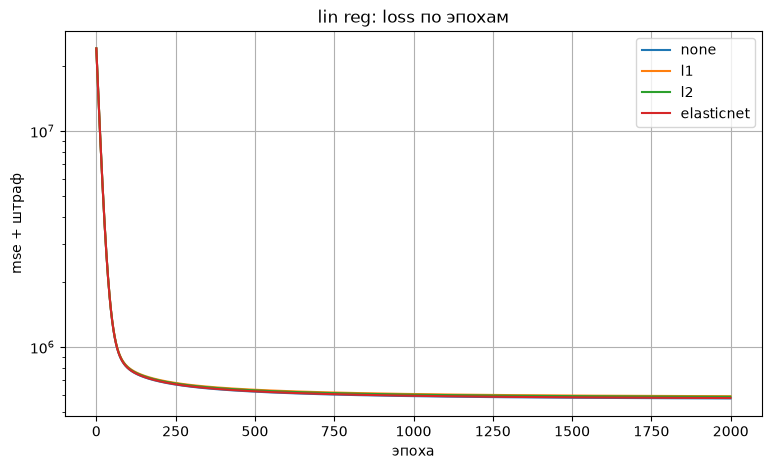

In [66]:
plt.figure(figsize=(9, 5))

for reg, model in linear_models.items():
    plt.plot(model.loss_history, label=reg)

plt.title("lin reg: loss по эпохам")
plt.xlabel("эпоха")
plt.ylabel("mse + штраф")
plt.yscale("log")
plt.legend()
plt.grid()
plt.show()

### Метрики на test

test не участвовал в выборе $\lambda$, поэтому теперь используем его для финального сравнения.

In [67]:
linear_metrics = []

for reg, model in linear_models.items():
    y_pred = model.predict(X_test_linear)

    mae = np.mean(np.abs(y_test_linear - y_pred))
    rmse = np.sqrt(np.mean((y_test_linear - y_pred) ** 2))
    r2 = 1 - np.sum((y_test_linear - y_pred) ** 2) / np.sum(
        (y_test_linear - y_test_linear.mean()) ** 2
    )

    ratio = model.l1_ratio if reg == "elasticnet" else np.nan
    linear_metrics.append([reg, model.lambda_, ratio, mae, rmse, r2])

linear_metrics = pd.DataFrame(
    linear_metrics,
    columns=["regularization", "lambda", "l1_ratio", "MAE", "RMSE", "R2"],
).set_index("regularization")
linear_metrics.round(3)

,lambda,l1_ratio,MAE,RMSE,R2
regularization,,,,,
none,0.000,NaN,574.157,766.579,0.84
l1,1.000,NaN,573.139,765.863,0.84
l2,0.001,NaN,573.248,765.403,0.84
elasticnet,0.001,0.75,573.927,766.277,0.84


### Веса

сравним общую величину весов и число почти нулевых коэффициентов. считаем, что $w \rightarrow 0$, если вес $|w| < 10^{-3}$.

In [68]:
linear_weight_stats = []

for reg, model in linear_models.items():
    weights = model.weights
    linear_weight_stats.append([
        reg,
        np.sum(np.abs(weights)),
        np.sqrt(np.sum(weights ** 2)),
        np.max(np.abs(weights)),
        np.sum(np.abs(weights) < 1e-3),
    ])

linear_weight_stats = pd.DataFrame(
    linear_weight_stats,
    columns=["regularization", "L1-норма", "L2-норма", "max |w|", "почти нулевых"],
).set_index("regularization")
linear_weight_stats.round(3)

,L1-норма,L2-норма,max |w|,почти нулевых
regularization,,,,
none,13833.698,3151.377,1583.316,0
l1,13594.854,3122.643,1582.356,0
l2,13664.494,3110.884,1560.305,0
elasticnet,13790.900,3141.140,1577.522,0


### Вывод

для `linReg` регуляризация немного улучшила результат (совсем немного). Лучший RMSE на test получился у L2: $765.4$ против $766.6$ без регуляризации. Для ElasticNet validation выбрал $\lambda = 0.001$ и `l1_ratio = 0.75`. Почти нулевых весов нет - выбранные $\lambda$ недостаточно велики для отбора признаков.

## Logistic Regression

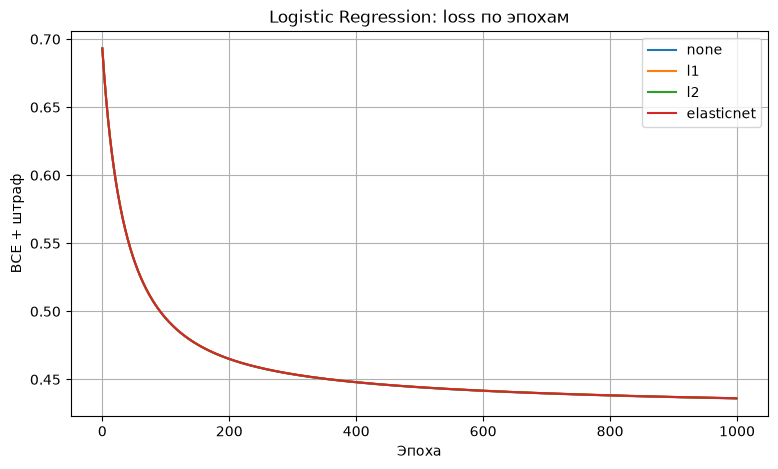

In [69]:
plt.figure(figsize=(9, 5))

for reg, model in logistic_models.items():
    plt.plot(model.loss_history, label=reg)

plt.title("Logistic Regression: loss по эпохам")
plt.xlabel("Эпоха")
plt.ylabel("BCE + штраф")
plt.legend()
plt.grid()
plt.show()

### Метрики на test

In [70]:
logistic_metrics = []

for reg, model in logistic_models.items():
    y_proba = model.predict_proba(X_test_logistic)
    y_pred = model.predict(X_test_logistic)

    tp = np.sum((y_test_logistic == 1) & (y_pred == 1))
    tn = np.sum((y_test_logistic == 0) & (y_pred == 0))
    fp = np.sum((y_test_logistic == 0) & (y_pred == 1))
    fn = np.sum((y_test_logistic == 1) & (y_pred == 0))

    accuracy = (tp + tn) / len(y_test_logistic)
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    f1 = 2 * precision * recall / (precision + recall)

    safe_proba = np.clip(y_proba, 1e-15, 1 - 1e-15)
    log_loss = -np.mean(
        y_test_logistic * np.log(safe_proba)
        + (1 - y_test_logistic) * np.log(1 - safe_proba)
    )

    logistic_metrics.append([
        reg, model.lambda_, model.l1_ratio if reg == "elasticnet" else np.nan,
        accuracy, precision, recall, f1, log_loss
    ])

logistic_metrics = pd.DataFrame(
    logistic_metrics,
    columns=["regularization", "lambda", "l1_ratio", "Accuracy", "Precision", "Recall", "F1", "LogLoss"],
).set_index("regularization")
logistic_metrics.round(4)

,lambda,l1_ratio,Accuracy,Precision,Recall,F1,LogLoss
regularization,,,,,,,
none,0.0,NaN,0.7711,0.769,0.783,0.7759,0.4612
l1,0.0,NaN,0.7711,0.769,0.783,0.7759,0.4612
l2,0.0,NaN,0.7711,0.769,0.783,0.7759,0.4612
elasticnet,0.0,0.75,0.7711,0.769,0.783,0.7759,0.4612


### Веса

In [71]:
logistic_weight_stats = []

for reg, model in logistic_models.items():
    weights = model.weights
    logistic_weight_stats.append([
        reg,
        np.sum(np.abs(weights)),
        np.sqrt(np.sum(weights ** 2)),
        np.max(np.abs(weights)),
        np.sum(np.abs(weights) < 1e-3),
    ])

logistic_weight_stats = pd.DataFrame(
    logistic_weight_stats,
    columns=["regularization", "L1-норма", "L2-норма", "max |w|", "почти нулевых"],
).set_index("regularization")
logistic_weight_stats.round(4)

,L1-норма,L2-норма,max |w|,почти нулевых
regularization,,,,
none,11.2621,3.0412,1.5696,0
l1,11.2523,3.0398,1.5690,0
l2,11.2546,3.0391,1.5683,0
elasticnet,11.2529,3.0396,1.5688,0


### Вывод

для `logReg` все варианты дали практически одинаковые метрики: Accuracy $\approx 0.771$, F1 $\approx 0.776$, LogLoss $\approx 0.461$. Для ElasticNet validation тоже выбрал `l1_ratio = 0.75`, но при очень маленьком $\lambda = 10^{-5}$ штраф почти не повлиял ни на качество, ни на веса.